 10%|▉         | 9976/100000 [00:30<02:53, 518.69it/s]

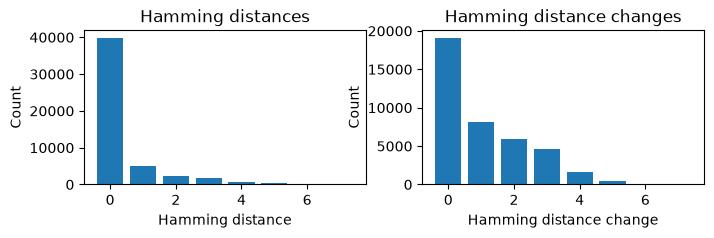

 20%|█▉        | 19976/100000 [00:49<02:27, 543.32it/s]

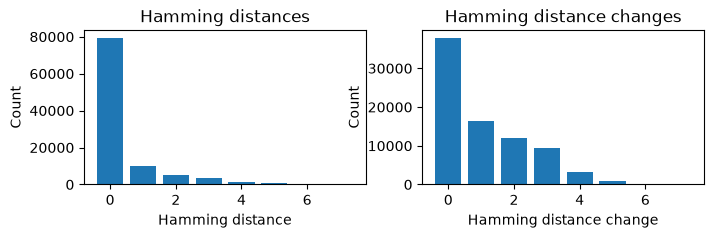

 30%|██▉       | 29997/100000 [01:12<03:59, 291.82it/s]

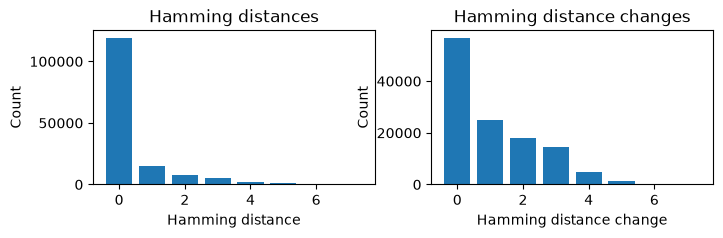

 40%|███▉      | 39979/100000 [01:48<03:35, 278.46it/s]

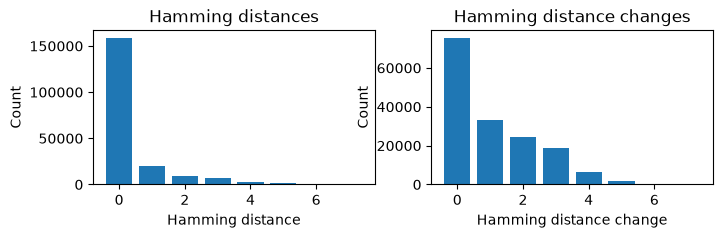

 50%|████▉     | 49991/100000 [02:24<03:00, 277.60it/s]

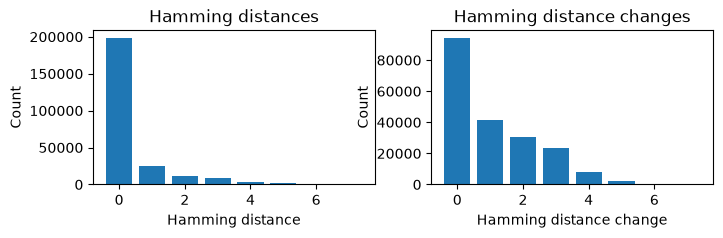

 60%|█████▉    | 59978/100000 [03:00<02:24, 276.63it/s]

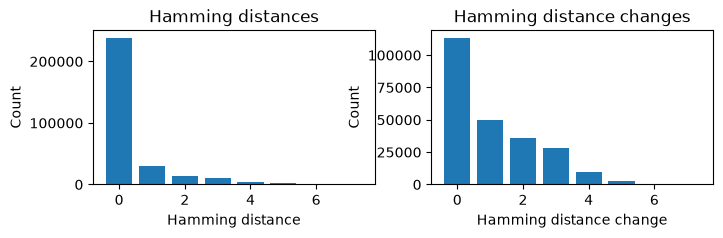

 70%|██████▉   | 69988/100000 [03:36<01:47, 279.19it/s]

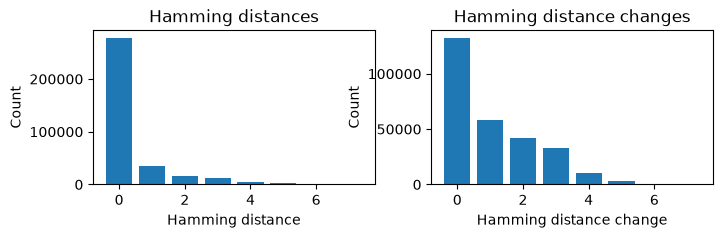

 80%|███████▉  | 79984/100000 [04:13<01:12, 277.04it/s]

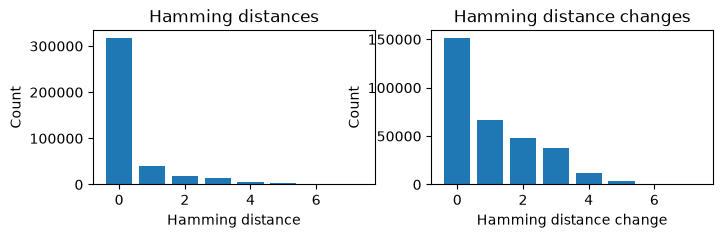

 90%|████████▉ | 89992/100000 [04:49<00:36, 274.95it/s]

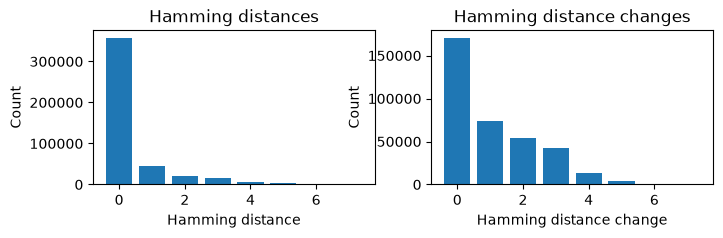

100%|██████████| 100000/100000 [05:26<00:00, 306.67it/s]


   id   step    noise noiseless  hamming_distance  hamming_distance_to_last
0   0  start  0000000   0000000                 0                       NaN
1   0  step1  0000000   0000000                 0                       0.0
2   0  step2  0000011   0000011                 0                       2.0
3   0  step3  0000000   0000000                 0                       2.0
4   0  step4  0000010   0000010                 0                       1.0
Prior 1: Probability of Hamming distance between noisy and noiseless bit string
{0: 0.794472, 4: 0.014152, 1: 0.102598, 5: 0.005938, 3: 0.032914, 2: 0.04787, 6: 0.001948, 7: 0.000108}


AttributeError: module 'matplotlib.pyplot' has no attribute 'subfigures'

In [ ]:
#using generated.csv, and the following table, generate the following 2 prior distributions given ancilla meassurements
basis = "Z"
#1) produce a prior for the propability of the Hamming distance between a noisy and noiseless bit string
#2) produce a prior for the probability of a Hamming distance change as one goes from one noiseless meassurement to the next

#string indexing, if basis = "Z"
#D7-D13: Noisless start meassurement
#D0-D6: Noisy start meassurement
#D14-D20: Noiseless step 1
#D28-D34: Noisy step 1
#D42-D48: Noiseless step 2
#D56-D62: Noisy step 2
#D70-D76: Noiseless step 3
#D84-D90: Noisy step 3
#D98-D104: Noiseless step 4
#D112-D118: Noisy step 4

#string indexing, if basis = "X"
#D7-D13: Noisless start meassurement
#D0-D6: Noisy start meassurement
#D21-D27: Noiseless step 1
#D33-D39: Noisy step 1
#D49-D55: Noiseless step 2
#D63-D69: Noisy step 2
#D77-D83: Noiseless step 3
#D91-D97: Noisy step 3
#D105-D111: Noiseless step 4
#D119-D125: Noisy step 4

#first, load the file and order the data
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

df = pd.read_csv("generated.csv")
df = df.sort_values(by="id")

noise_cols = {
    "Z": {
        "start": ["D0","D1","D2","D3","D4","D5","D6"],
        "step1": ["D28","D29","D30","D31","D32","D33","D34"],
        "step2": ["D56","D57","D58","D59","D60","D61","D62"],
        "step3": ["D84","D85","D86","D87","D88","D89","D90"],
        "step4": ["D112","D113","D114","D115","D116","D117","D118"]
    },
    "X": {
        "start": ["D0","D1","D2","D3","D4","D5","D6"],
        "step1": ["D33","D34","D35","D36","D37","D38","D39"],
        "step2": ["D63","D64","D65","D66","D67","D68","D69"],
        "step3": ["D91","D92","D93","D94","D95","D96","D97"],
        "step4": ["D119","D120","D121","D122","D123","D124","D125"]
    }
}

noiseless_cols = {
    "Z": {
        "start": ["D7","D8","D9","D10","D11","D12","D13"],
        "step1": ["D14","D15","D16","D17","D18","D19","D20"],
        "step2": ["D42","D43","D44","D45","D46","D47","D48"],
        "step3": ["D70","D71","D72","D73","D74","D75","D76"],
        "step4": ["D98","D99","D100","D101","D102","D103","D104"]
    },
    "X": {
        "start": ["D7","D8","D9","D10","D11","D12","D13"],
        "step1": ["D21","D22","D3","D24","D25","D26","D27"],
        "step2": ["D49","D50","D51","D52","D53","D54","D55"],
        "step3": ["D77","D78","D79","D80","D81","D82","D83"],
        "step4": ["D105","D106","D107","D108","D109","D110","D111"]
    }
}

if basis == "X":#first 100000 rows of the dataframe are for basis X, the rest are for basis Z
    df = df.iloc[:100000]
else:
    df = df.iloc[100000:]

#generate data table
data = []
hamming_distances = {}
hamming_distance_changes = {}
for i, row in tqdm(df.iterrows(), total=df.shape[0]):
    for step in ["start", "step1", "step2", "step3", "step4"]:
        if basis == "Z":
            noise = row[noise_cols["Z"][step]]
            noiseless = row[noiseless_cols["Z"][step]]
        else:
            noise = row[noise_cols["X"][step]]
            noiseless = row[noiseless_cols["X"][step]]
        noise_str = "".join(map(str, noise))
        noiseless_str = "".join(map(str, noiseless))
        hd = sum(n != nl for n, nl in zip(noise_str, noiseless_str))
        last = data[-1] if data else None
        last_noiseless = last["noiseless"] if (last and step != "start") else None
        hd_tolast = sum(nl != lnl for nl, lnl in zip(noiseless_str, last_noiseless)) if last_noiseless else None
        data.append({
            "id": i,
            "step": step,
            "noise": noise_str,
            "noiseless": noiseless_str,
            "hamming_distance": hd,
            "hamming_distance_to_last": hd_tolast
        })
        if hd not in hamming_distances:
            hamming_distances[hd] = 0
        hamming_distances[hd] += 1
        if hd_tolast is not None:
            if hd_tolast not in hamming_distance_changes:
                hamming_distance_changes[hd_tolast] = 0
            hamming_distance_changes[hd_tolast] += 1
    #every 10000 rows, do a histrogram of the hamming distances
    if i % 10000 == 0 and i > 0:
        fig, axs = plt.subplots(1, 2, figsize=(8, 2))
        axs[0].bar(hamming_distances.keys(), hamming_distances.values())
        axs[0].set_title("Hamming distances")
        axs[0].set_xlabel("Hamming distance")
        axs[0].set_ylabel("Count")
        axs[1].bar(hamming_distance_changes.keys(), hamming_distance_changes.values())
        axs[1].set_title("Hamming distance changes")
        axs[1].set_xlabel("Hamming distance change")
        axs[1].set_ylabel("Count")
        plt.show()
df_data = pd.DataFrame(data)
print(df_data.head())

Prior 1: Probability of Hamming distance between noisy and noiseless bit string
{0: 0.794472, 4: 0.014152, 1: 0.102598, 5: 0.005938, 3: 0.032914, 2: 0.04787, 6: 0.001948, 7: 0.000108}


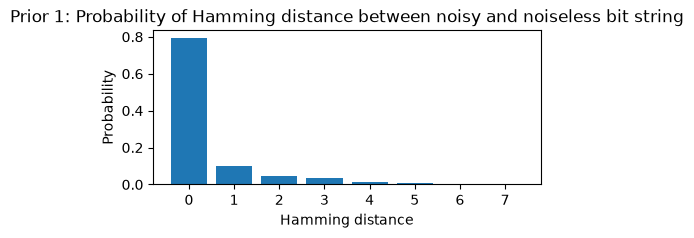

Prior 2: Probability of Hamming distance change between noiseless measurements
{0: 0.47411, 2: 0.151165, 1: 0.2061275, 3: 0.117615, 4: 0.03862, 5: 0.010235, 6: 0.0019975, 7: 0.00013}


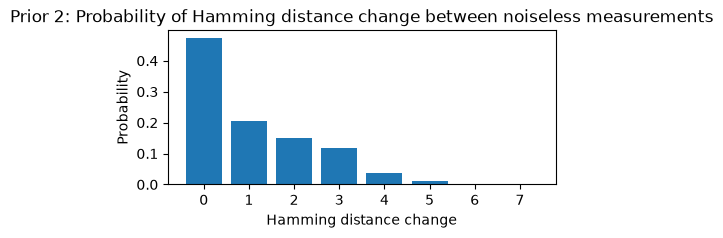

In [4]:

#use hamming_distances to generate the first prior
total = sum(hamming_distances.values())
prior1 = {hd: count / total for hd, count in hamming_distances.items()}
print("Prior 1: Probability of Hamming distance between noisy and noiseless bit string")
print(prior1)

#plot it
plt.figure(figsize=(5, 2))
plt.bar(prior1.keys(), prior1.values())
plt.title("Prior 1: Probability of Hamming distance between noisy and noiseless bit string")
plt.xlabel("Hamming distance")
plt.ylabel("Probability")
plt.show()

#generate the second prior
total = sum(hamming_distance_changes.values())
prior2 = {hd: count / total for hd, count in hamming_distance_changes.items()}
print("Prior 2: Probability of Hamming distance change between noiseless measurements")
print(prior2)

#plot it
plt.figure(figsize=(5, 2))
plt.bar(prior2.keys(), prior2.values())
plt.title("Prior 2: Probability of Hamming distance change between noiseless measurements")
plt.xlabel("Hamming distance change")
plt.ylabel("Probability")
plt.show()

In [3]:
#print a table of the priors
print("Prior 1: Probability of Hamming distance between noisy and noiseless bit string")
print("Hamming distance\tProbability")
for hd, prob in prior1.items():
    print(f"{hd}\t{prob:.4f}")

print("\nPrior 2: Probability of each logical error")
print("Logical error\tProbability")
for le, prob in prior2.items():
    print(f"{le}\t{prob:.4f}")

Prior 1: Probability of Hamming distance between noisy and noiseless bit string
Hamming distance	Probability
0	0.7945
4	0.0142
1	0.1026
5	0.0059
3	0.0329
2	0.0479
6	0.0019
7	0.0001

Prior 2: Probability of each logical error
Logical error	Probability


NameError: name 'prior2' is not defined